In [27]:
import numpy as np
from cosmoTransitions.tunneling1D import SingleFieldInstanton
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy import optimize as optimize
import scipy.integrate as integrate
from scipy import interpolate, special


####Some definitions##
v2 = 246.**2 
mh=125
v=246
alpha=1/137 #fine structure constant
sinthw=np.sqrt(0.223) #sine of Weinberg angle
g1=np.sqrt(4*np.pi*alpha/(1-sinthw**2)) ## U(1)_Y gauge coupling constant
g=np.sqrt(4*np.pi*alpha)/sinthw #SU(2)_L gauge coupling constant
Mplanck=2.4*10**18 #reduced planck mass
mZ=np.sqrt(v**2/4*(g**2+g1**2))###Z boson mass

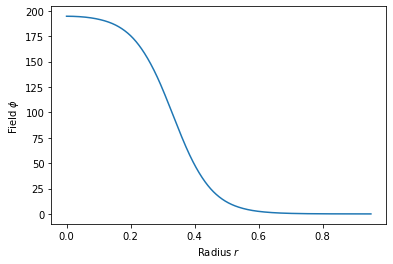

[0.00000000e+00 1.15408010e-08 1.43986259e-06 ... 1.42404836e-03
 1.42547668e-03 1.42690501e-03]


In [28]:
#Definition of the potential#
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
alpha = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
T = 93.
def V(phi): return 0.5*gamma*(T**2-T0**2)*phi**2-1/3*alpha*T*phi**3+0.25*lam*phi**4
def dV(phi): return gamma*(T**2-T0**2)*phi-alpha*T*phi**2+lam*phi**3

#critical bubble#
xi = np.array(range(25000))*0.01
Vmin = np.amin(V(xi))
vt = xi[np.where(V(xi) == Vmin)[0]][0] ##find location of the global minimum
profile = SingleFieldInstanton(vt, 0.0, V, dV).findProfile(npoints=1000)
plt.plot(profile.R, profile.Phi)
plt.xlabel(r"Radius $r$")
plt.ylabel(r"Field $\phi$")
plt.show()
print(profile.R*dr)

In [52]:
print(vt)

198.51


13333.333333333334


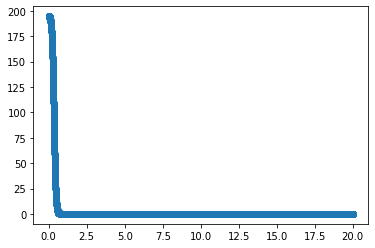

In [12]:
plt.scatter(r,phi0)
print(20/dr)

13333.333333333334


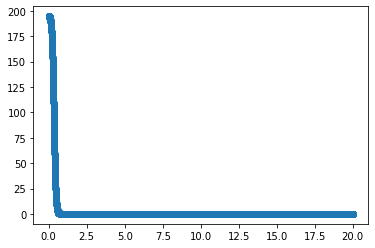

In [12]:
plt.scatter(r,phi0)
print(20/dr)

In [26]:
#Thermodynamical quantities#
def eps(field, temp):
    gst = 106.75
    a = gst*(math.pi**2)/90
    T = temp
    return 3*a*temp**4+ V(field)- T*dV(field)

eps(10,120)

7282159534.910547

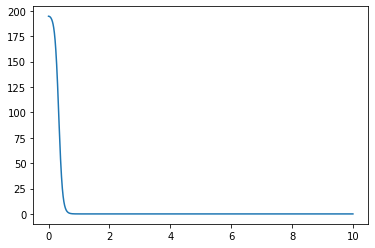

In [87]:
#initialization of the evolution#
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value=(0), bounds_error=False)
dr=0.0005
r  = np.array(range(1, int(np.floor(10/dr))))*dr
phi0 = fphi(r/1.01)
phi2 = np.zeros(r.size)
plt.plot(r,phi0)
plt.show()

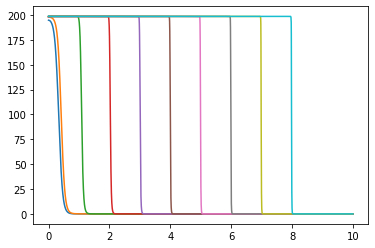

In [88]:
####Solving equation (8) of arxiv:9512202 with \eta=0
###Lattice approach:

dt = 0.0001
phi=phi0
d1 = ((r + dr)**2 + r**2)/(2*dr**2*r**2)
d2 = ((r - dr)**2 + r**2)/(2*dr**2*r**2)
for i in range(100000):#--------------------------------------------------iterate over time
    #------1 step evolution
    phi = 0.5*dt*phi2 + phi
    lphi = np.append(phi[1:],0)
    rphi = np.append(vt,phi[:-1])
    #------2nd step evolution 
    phi2 = phi2 + dt*( d1*(lphi-phi)-d2*(phi-rphi) - dV(phi) )
    #-------3rd step evolution
    phi = 0.5*dt*phi2 +phi
    if(i%10000==0):
        plt.plot(r,phi)

   

In [61]:
print(phi0[0],vt)

194.64262974649753 198.51


In [50]:
print(d1)

[1000.          650.          555.55555556  512.5         488.
  472.22222222  461.2244898   453.125       446.91358025  442.
  438.01652893  434.72222222  431.95266272  429.59183673  427.55555556
  425.78125     424.22145329  422.83950617  421.6066482   420.5
  419.50113379  418.59504132  417.76937618  417.01388889  416.32
  415.68047337  415.08916324  414.54081633  414.03091558  413.55555556
  413.11134235  412.6953125   412.30486685  411.93771626  411.59183673
  411.2654321   410.95690285  410.66481994  410.3879027   410.125
  409.87507436  409.63718821  409.41049216  409.19421488  408.98765432
  408.79017013  408.601177    408.42013889  408.24656393  408.08
  407.92003076  407.76627219  407.61836953  407.47599451  407.33884298
  407.20663265  407.07910126  406.95600476  406.83711577  406.72222222
  406.61112604  406.50364204  406.39959688  406.29882812  406.20118343
  406.10651974  406.01470261  405.92560554  405.83910943  405.75510204
  405.67347748  405.5941358   405.51698255  40